In [15]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

In [6]:
path_realdata="/Odyssey/public/altimetry_traces/2010_2023/gridded/sla_l3_all_2010_2023_0.25deg_convl4.nc"
# "/Odyssey/public/altimetry_traces/2010_2019/gridded_0.25deg/sla_unfiltered_0.25deg.nc"
# "/Odyssey/public/data_challenge_ssh_ose/data/gridded_alongtrack/sla_filtered_0.25deg.nc"

path_simulation_tgt="/Odyssey/public/glorys/reanalysis/glorys12_2010_2019_daily_sla_4th_target_gridded_alongtrack.nc"

path_simulation_inp="/Odyssey/public/glorys/reanalysis/glorys12_2010_2019_daily_sla_4th_input_gridded_alongtrack.nc"

In [16]:
import xarray as xr

ds = xr.open_dataset("/SCRATCH/n23nguye/mapping_2024/alongtrack_onlynadirs_real_2023-12-01_2025-01-31.nc")
print(ds)
print(ds["sla"])

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 428, latitude: 720, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-12-01 2023-12-02 ... 2025-01-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
Data variables:
    sla        (time, latitude, longitude) float32 2GB ...
<xarray.DataArray 'sla' (time: 428, latitude: 720, longitude: 1440)> Size: 2GB
[443750400 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-12-01 2023-12-02 ... 2025-01-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9


In [18]:
import xarray as xr

ds = xr.open_dataset("/Odyssey/public/data_challenge_ssh_ose/data/gridded_alongtrack/sla_filtered_0.25deg.nc")
print(ds)
print(ds["sla_filtered"])

<xarray.Dataset> Size: 2GB
Dimensions:       (time: 427, lat: 648, lon: 1488)
Coordinates:
  * time          (time) datetime64[ns] 3kB 2018-12-01 2018-12-02 ... 2020-01-31
  * lat           (lat) float64 5kB -79.88 -79.62 -79.38 ... 81.38 81.62 81.88
  * lon           (lon) float64 12kB -185.9 -185.6 -185.4 ... 185.4 185.6 185.9
Data variables:
    sla_filtered  (time, lat, lon) float32 2GB ...
<xarray.DataArray 'sla_filtered' (time: 427, lat: 648, lon: 1488)> Size: 2GB
[411723648 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 3kB 2018-12-01 2018-12-02 ... 2020-01-31
  * lat      (lat) float64 5kB -79.88 -79.62 -79.38 -79.12 ... 81.38 81.62 81.88
  * lon      (lon) float64 12kB -185.9 -185.6 -185.4 ... 185.4 185.6 185.9


In [7]:
ds_real = xr.open_dataset(path_realdata)
ds_sim = xr.open_dataset(path_simulation_tgt)

In [19]:
import xarray as xr
m = xr.open_dataset('/Odyssey/public/_transit_zone_/mask-A.nc')
print(m)            # dims, variables, coords
print(m.dims)       # is there a 'time' dimension?
print(m.attrs)      # any mention of 2019?

<xarray.Dataset> Size: 1GB
Dimensions:            (time: 14138044)
Coordinates:
  * time               (time) datetime64[ns] 113MB 2019-01-01T00:04:18.619014...
Data variables: (12/13)
    cycle              (time) float32 57MB ...
    track              (time) float32 57MB ...
    sla_unfiltered     (time) float64 113MB ...
    sla_filtered       (time) float64 113MB ...
    dac                (time) float64 113MB ...
    ocean_tide         (time) float64 113MB ...
    ...                 ...
    lwe                (time) float64 113MB ...
    mdt                (time) float64 113MB ...
    tpa_correction     (time) float64 113MB ...
    longitude          (time) float64 113MB ...
    latitude           (time) float64 113MB ...
    msla_interpolated  (time) float64 113MB ...
FrozenMappingWarningOnValuesAccess({'time': 14138044})
{}


In [8]:
print("ds_real:", ds_real)
print("******************************************************************")
print("ds_sim:", ds_sim)

ds_real: <xarray.Dataset> Size: 106GB
Dimensions:         (time: 5113, lat: 720, lon: 1440)
Coordinates:
  * time            (time) datetime64[ns] 41kB 2010-01-01 ... 2023-12-31
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.25 89.5 89.75
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    mdt             (time, lat, lon) float32 21GB ...
    sla_filtered    (time, lat, lon) float32 21GB ...
    ssh             (time, lat, lon) float32 21GB ...
    sla_unfiltered  (time, lat, lon) float32 21GB ...
    lwe             (time, lat, lon) float32 21GB ...
******************************************************************
ds_sim: <xarray.Dataset> Size: 30GB
Dimensions:    (time: 3652, latitude: 720, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 29kB 2010-01-01 2010-01-02 ... 2019-12-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float64 12kB -179.9

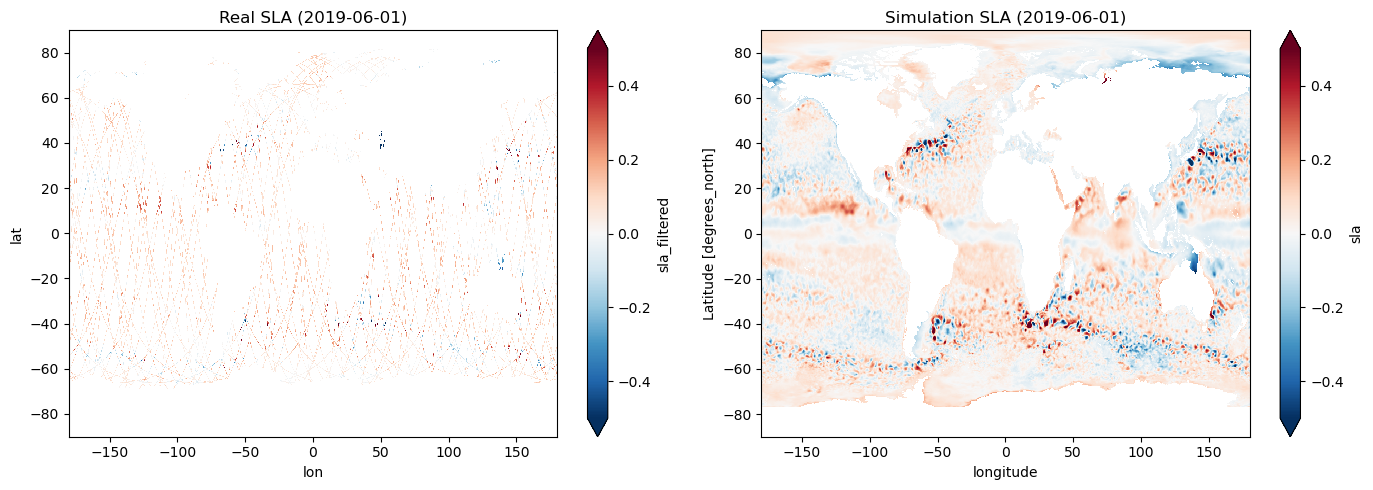

In [9]:
date = "2019-06-01"  # change as needed

real_day = ds_real.sel(time=date)#, method="nearest")
sim_day  = ds_sim.sel(time=date)#, method="nearest")

real_sla = real_day["sla_filtered"]
sim_sla  = sim_day["sla"]

vmin = -0.5#min(real_sla.min().item(), sim_sla.min().item())
vmax = 0.5#max(real_sla.max().item(), sim_sla.max().item())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Real data
real_sla.plot(ax=axes[0], cmap="RdBu_r", vmin=vmin, vmax=vmax)
axes[0].set_title(f"Real SLA ({date})")

# Simulation data
sim_sla.plot(ax=axes[1], cmap="RdBu_r", vmin=vmin, vmax=vmax)
axes[1].set_title(f"Simulation SLA ({date})")

plt.tight_layout()
plt.show()


In [9]:
import xarray as xr

mask = xr.open_dataset(
    "/SCRATCH/n23nguye/mapping_2024/mask_onlynadirs_2024_365d.nc"
)

print(mask)
print(mask.dims)

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 365, latitude: 720, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
Data variables:
    mask       (time, latitude, longitude) float32 2GB ...
FrozenMappingWarningOnValuesAccess({'time': 365, 'latitude': 720, 'longitude': 1440})


In [11]:
mask.mask.values

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       ...,

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan

In [14]:
np.isfinite(mask)

<xarray.Dataset> Size: 378MB
Dimensions:    (time: 365, latitude: 720, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
Data variables:
    mask       (time, latitude, longitude) bool 378MB False False ... False

In [5]:
inp = xr.open_dataset(
    "/SCRATCH/n23nguye/glorys12_2010_2019_daily_sla_4th_input_gridded_alongtrack.nc"
)

print(inp)


<xarray.Dataset> Size: 15GB
Dimensions:  (time: 3652, lat: 720, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 29kB 2010-01-01 2010-01-02 ... 2019-12-31
  * lat      (lat) float64 6kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Data variables:
    sla      (time, lat, lon) float32 15GB ...


In [2]:
tgt = xr.open_dataset(
    "/SCRATCH/n23nguye/glorys12_2010_2019_daily_sla_4th_target_gridded_alongtrack.nc"
)

print(tgt)
print(tgt.dims)

<xarray.Dataset> Size: 30GB
Dimensions:    (time: 3652, latitude: 720, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 29kB 2010-01-01 2010-01-02 ... 2019-12-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float64 12kB -179.9 -179.6 -179.4 ... 179.6 179.9
Data variables:
    sla        (time, latitude, longitude) float64 30GB ...
Attributes:
    history:                   2023/06/01 16:20:05 MERCATOR OCEAN Netcdf crea...
    institution:               MERCATOR OCEAN
    references:                http://www.mercator-ocean.fr
    comment:                   CMEMS product
    title:                     daily mean fields from Global Ocean Physics An...
    source:                    MERCATOR GLORYS12V1
    Conventions:               CF-1.4
    copernicusmarine_version:  2.0.0
FrozenMappingWarningOnValuesAccess({'time': 3652, 'latitude': 720, 'longitude': 1440})


In [7]:
print(xr.open_dataset('/SCRATCH/n23nguye/glorys12_2010_2019_daily_sla_4th_target_gridded_alongtrack.nc').sizes)

Frozen({'time': 3652, 'latitude': 720, 'longitude': 1440})
